In [1]:
from collections import defaultdict
import os

import numpy as np
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import cv2
import matplotlib.pyplot as plt

In [2]:
# Ensure that plotly renders inside the Jupyter notebook
pio.renderers.default = 'notebook_connected'

In [3]:
base_path = "/mnt/pg-fs01/Current/DB/ObjectDetectionV3"
df = pd.read_csv(os.path.join(base_path, "images.csv"))
df.shape

(1032, 6)

In [4]:
df.head()

,id,name,width,height,batch,folder
0,bdd640fb-0667-4ad1-9c80-317fa3b1799d,Cam3_H243_discount_14.png,640.0,480.0,batch1_10.5,batch1
1,fc377a4c-4a15-444d-85e7-ce8a3a578a8e,Cam3_H243_discount_15.png,640.0,480.0,batch1_10.5,batch1
2,ff50bde4-3825-47b8-9cab-cc97663f1c97,Cam3_H243_discount_16.png,640.0,480.0,batch1_10.5,batch1
3,5cec4eb5-edd9-4831-9ca3-5cfb04fc6d82,Cam3_H243_discount_17.png,640.0,480.0,batch1_10.5,batch1
4,b92da22b-21df-406f-8a0b-3c3336d8393a,Cam3_H243_discount_18.png,640.0,480.0,batch1_10.5,batch1


In [5]:
names = df["name"].values
names = np.unique(names)
names.shape

(970,)

Cam3_H250 - 177:
- Cam3_H250_spacesks_MR1 - 125
- Cam3_H250_spacesks_os1 - 51
- Cam3_H250_spaceKS - 1


- Cam3_H243_discount: 19
- Cam3_H245_discount: 55
- Cam3_H245_spaceKS: 5
- Cam3_H230_spaceKS_desks1: 5
- Cam3_H230_spaceKS_objects

In [6]:
tst_names = [
    'Cam3_H243_discount_14.png', 'Cam3_H243_discount_15.png',
    'Cam3_H243_discount_16.png', 'Cam3_H243_discount_17.png',
    'Cam3_H243_discount_18.png', 'Cam3_H243_discount_19.png',
    'Cam3_H245_discount_1.png', 'Cam3_H245_discount_2.png',
    'Cam3_H245_discount_3.png', 'Cam3_H245_discount_4.png',
    'Cam3_H245_discount_10.png', 'Cam3_H245_discount_11.png',
    'Cam3_H245_discount_12.png', 'Cam3_H245_discount_13.png',
    'Cam3_H245_discount_14.png', 'Cam3_H245_discount_5.png',
    'Cam3_H245_discount_6.png', 'Cam3_H245_discount_7.png',
    'Cam3_H245_discount_8.png', 'Cam3_H245_discount_9.png',
    'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png',
    'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png',
    'Cam2_H255_discaunt_29012024_2024-02-06-11h11m13s016.png',
    'Cam2_H255_discaunt_29012024_2024-02-06-11h11m15s315.png',
    'Cam2_H255_discaunt_29012024_2024-02-06-11h11m20s109.png'
]

In [7]:
class Node:
    def __init__(self, prefix, count, parrent_prefix=""):
        self.prefix = prefix
        self.parrent_prefix = parrent_prefix
        self.leafs = []
        self.count = count

        self.full_name = f"{self.parrent_prefix}_{self.prefix}" if self.parrent_prefix else self.prefix

    def __str__(self):
        return f"'{self.full_name}': {self.count}"

def build_tree(filenames, prefix="", parrent_prefix=""):
    if prefix == "Cam3_H250_spaceKS":
            pass
    # print(prefix, len(filenames), filenames[:3])
    node = Node(prefix, len(filenames), parrent_prefix)
    leafs = []
    
    if len(filenames) == 1 and filenames[0] == "":
        return node
    
    filename_parts = [filename.split("_", 1) for filename in filenames]
    prefixes, suffixes= zip(*[i if len(i) > 1 else i + [""] for i in filename_parts])
    
    filename_parts = [filename.split("_", 1) for filename in filenames]
    prefixes, suffixes = zip(*[i if len(i) > 1 else i + [""] for i in filename_parts])

    uprefixes, inverse_idxs = np.unique(prefixes, return_inverse=True)
    
    for idx, uprefix in enumerate(uprefixes):
        leaf = build_tree(np.array(suffixes)[inverse_idxs == idx], uprefix, node.full_name)
        leafs.append(leaf)

    node.leafs = leafs
    return node

def print_tree(node, level=0):
    print("  " * level, node)
    for leaf in node.leafs:
        print_tree(leaf, level + 1)


def print_tree_upd(node, level=0, is_last=False, prefix=''):
    if level == 0:
        print(node)
    else:
        print(prefix, '└───' if is_last else '├───', node, sep='')
    prefix += '    ' if is_last else '│   '
    for i, leaf in enumerate(node.leafs):
        print_tree_upd(leaf, level + 1, i == len(node.leafs) - 1, prefix)

In [8]:
tst_root = build_tree(tst_names)
print_tree_upd(tst_root)

'': 25
│   ├───'Cam2': 5
│   │   └───'Cam2_H255': 5
│   │       └───'Cam2_H255_discaunt': 5
│   │           └───'Cam2_H255_discaunt_29012024': 5
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m13s016.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m15s315.png': 1
│   │               └───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m20s109.png': 1
│   └───'Cam3': 20
│       ├───'Cam3_H243': 6
│       │   └───'Cam3_H243_discount': 6
│       │       ├───'Cam3_H243_discount_14.png': 1
│       │       ├───'Cam3_H243_discount_15.png': 1
│       │       ├───'Cam3_H243_discount_16.png': 1
│       │       ├───'Cam3_H243_discount_17.png': 1
│       │       ├───'Cam3_H243_discount_18.png': 1
│       │       └───'Cam3_H243_discount_19.png': 1
│       └───'Cam3_H245': 14
│         

In [9]:
root = build_tree(names)
print_tree_upd(root)

'': 970
│   ├───'2017': 15
│   │   ├───'2017_06': 12
│   │   │   └───'2017_06_21': 12
│   │   │       └───'2017_06_21_DL': 12
│   │   │           └───'2017_06_21_DL_SL': 12
│   │   │               └───'2017_06_21_DL_SL_Farnel02': 12
│   │   │                   └───'2017_06_21_DL_SL_Farnel02_H270': 12
│   │   │                       └───'2017_06_21_DL_SL_Farnel02_H270_15m': 12
│   │   │                           ├───'2017_06_21_DL_SL_Farnel02_H270_15m_1495096750': 2
│   │   │                           │   └───'2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f': 2
│   │   │                           │       ├───'2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f_00312': 1
│   │   │                           │       │   └───'2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f_00312_02122-11': 1
│   │   │                           │       │       └───'2017_06_21_DL_SL_Farnel02_H270_15m_1495096750_f_00312_02122-11_1985.jpg': 1
│   │   │                           │       └───'2017_06_21_DL_SL_Farnel0

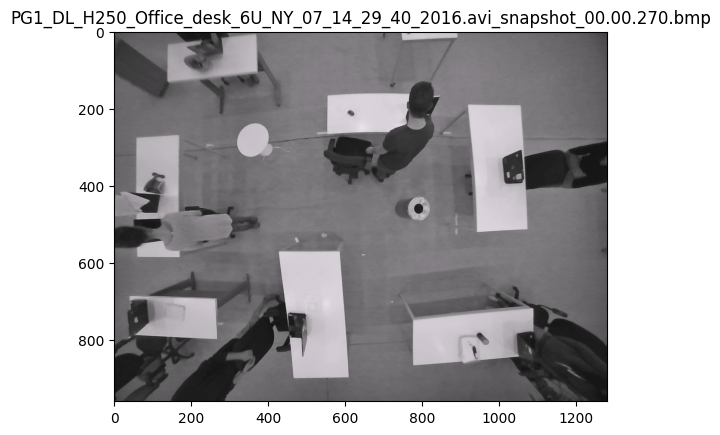

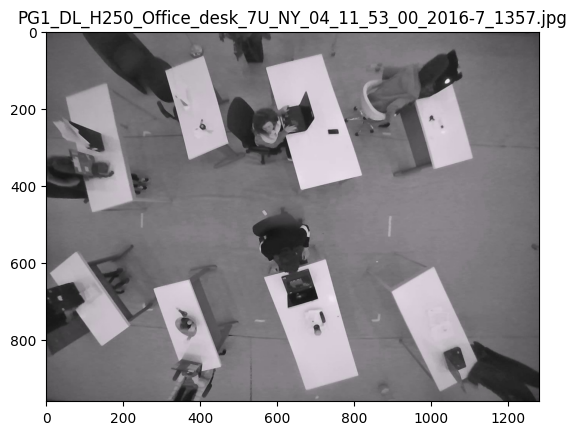

In [10]:
tmp = [
    'PG1_DL_H250_Office_desk_6U_NY_07_14_29_40_2016.avi_snapshot_00.00.270.bmp',
    'PG1_DL_H250_Office_desk_7U_NY_04_11_53_00_2016-7_1357.jpg'
]

for i in tmp:
    row = df[df["name"] == i]
    pth = os.path.join(base_path, row["batch"].iloc[0], row["folder"].iloc[0], i)
    img = cv2.cvtColor(cv2.imread(pth), cv2.COLOR_BGR2RGB)
    plt.figure()
    plt.imshow(img)
    plt.title(i)

level 5  - maximum

In [11]:
print_tree_upd(tst_root)

'': 25
│   ├───'Cam2': 5
│   │   └───'Cam2_H255': 5
│   │       └───'Cam2_H255_discaunt': 5
│   │           └───'Cam2_H255_discaunt_29012024': 5
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m13s016.png': 1
│   │               ├───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m15s315.png': 1
│   │               └───'Cam2_H255_discaunt_29012024_2024-02-06-11h11m20s109.png': 1
│   └───'Cam3': 20
│       ├───'Cam3_H243': 6
│       │   └───'Cam3_H243_discount': 6
│       │       ├───'Cam3_H243_discount_14.png': 1
│       │       ├───'Cam3_H243_discount_15.png': 1
│       │       ├───'Cam3_H243_discount_16.png': 1
│       │       ├───'Cam3_H243_discount_17.png': 1
│       │       ├───'Cam3_H243_discount_18.png': 1
│       │       └───'Cam3_H243_discount_19.png': 1
│       └───'Cam3_H245': 14
│         

In [14]:
def get_all_leafs(node):
    if len(node.leafs) == 0:
        return [node]
    else:
        leafs = []
        for leaf in node.leafs:
            leafs += get_all_leafs(leaf)
    return leafs

tst_leafs = get_all_leafs(tst_root)
len(tst_leafs)

25

In [15]:
leafs = get_all_leafs(root)
len(leafs), len(set([leaf.full_name for leaf in leafs]).difference(names)) == 0

(970, True)

Stop criteria:
- `level >= 5`
- `sum([leaf.count for leaf in node.leafs]) == len(node.leafs)`

In [31]:
def get_all_leaf_full_names(node):
    return [leaf.full_name for leaf in get_all_leafs(node)]

def is_next_level_has_the_same_count(node):
    return len(node.leafs) == 1 and node.count == node.leafs[0].count

def split_by_groups(node, level=0, prev_count=-1):
    if level >= 5:
        return get_all_leaf_full_names(node)
    elif sum([leaf.count for leaf in node.leafs]) == len(node.leafs):
        return get_all_leaf_full_names(node)
    elif is_next_level_has_the_same_count(node):
        return get_all_leaf_full_names(node)
    else:
        groups = {}
        for leaf in node.leafs:
            groups[leaf.full_name] = split_by_groups(leaf, level + 1, node.count)
        
        return groups

In [39]:
def get_all_leaf_full_names(node):
    return [leaf.full_name for leaf in get_all_leafs(node)]

def is_next_level_has_the_same_count(node):
    return len(node.leafs) == 1 and node.count == node.leafs[0].count

def split_by_groups(node, groups, level=0, prev_count=-1):
    if level >= 5:
        groups[node.full_name] = get_all_leaf_full_names(node)
        # return get_all_leaf_full_names(node)
    elif sum([leaf.count for leaf in node.leafs]) == len(node.leafs):
        groups[node.full_name] = get_all_leaf_full_names(node)
        # return get_all_leaf_full_names(node)
    elif is_next_level_has_the_same_count(node):
        groups[node.full_name] = get_all_leaf_full_names(node)
        # return get_all_leaf_full_names(node)
    else:
        for leaf in node.leafs:
            split_by_groups(leaf, groups, level + 1, node.count)


In [42]:
tst_groups = {}
split_by_groups(tst_root, tst_groups)
tst_groups

{'Cam2': ['Cam2_H255_discaunt_29012024_2024-02-06-11h11m07s670.png',
  'Cam2_H255_discaunt_29012024_2024-02-06-11h11m10s095.png',
  'Cam2_H255_discaunt_29012024_2024-02-06-11h11m13s016.png',
  'Cam2_H255_discaunt_29012024_2024-02-06-11h11m15s315.png',
  'Cam2_H255_discaunt_29012024_2024-02-06-11h11m20s109.png'],
 'Cam3_H243': ['Cam3_H243_discount_14.png',
  'Cam3_H243_discount_15.png',
  'Cam3_H243_discount_16.png',
  'Cam3_H243_discount_17.png',
  'Cam3_H243_discount_18.png',
  'Cam3_H243_discount_19.png'],
 'Cam3_H245': ['Cam3_H245_discount_1.png',
  'Cam3_H245_discount_10.png',
  'Cam3_H245_discount_11.png',
  'Cam3_H245_discount_12.png',
  'Cam3_H245_discount_13.png',
  'Cam3_H245_discount_14.png',
  'Cam3_H245_discount_2.png',
  'Cam3_H245_discount_3.png',
  'Cam3_H245_discount_4.png',
  'Cam3_H245_discount_5.png',
  'Cam3_H245_discount_6.png',
  'Cam3_H245_discount_7.png',
  'Cam3_H245_discount_8.png',
  'Cam3_H245_discount_9.png']}

In [43]:
groups = {}
split_by_groups(root, groups)

len(groups), sum([len(group) for group in groups.values()]) == names.shape[0]

(120, True)